# M2-T03: PCA Analysis on EuroSAT Multispectral Dataset

## 1. Introduction

This notebook investigates Principal Component Analysis (PCA)
on the 13-band EuroSAT Multispectral dataset.

The main objective is to analyze spectral dimensionality
reduction and determine how many principal components are
required to preserve most of the information contained in
the original Sentinel-2 spectral bands.

## Dataset Specifications

- Dataset: EuroSAT Multispectral
- Number of images: 27,000
- Number of classes: 10
- Original spectral bands: 13
- Image dimensions: 64 × 64
- Image format: TIFF

## Objectives

1. Load the existing dataset using the project's data pipeline.
2. Apply feature standardization.
3. Perform PCA on the 13 spectral bands.
4. Calculate explained variance ratios.
5. Calculate cumulative explained variance.
6. Identify the components required to retain 90%, 95%, and 99%
   of the total variance.

## Methodology

PCA is applied at the pixel level.

Each pixel is represented by 13 spectral measurements,
one for each Sentinel-2 band.

The resulting principal components represent new spectral
features that capture the maximum possible variance in
the original data.

To prevent data leakage, the scaler and PCA transformer
are fitted using training data only.

In [1]:
import sys
print(sys.executable)

c:\Users\HP\AppData\Local\Python\pythoncore-3.14-64\python.exe


In [2]:
# Standard libraries
import sys
import random
from pathlib import Path

# Data processing
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt

# Machine learning
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import IncrementalPCA

# Saving preprocessing objects
import joblib

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
import sys
from pathlib import Path

# Project root
PROJECT_ROOT = Path(r"C:\Users\HP\Desktop\NHA-5-151")

# Add project root to Python path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Verify project structure
assert (PROJECT_ROOT / "src" / "dataset.py").exists(), "dataset.py not found!"

print("Project Root:", PROJECT_ROOT)
print("Project path is correct!")

Project Root: C:\Users\HP\Desktop\NHA-5-151
Project path is correct!


In [5]:
import sys

print("Python executable:", sys.executable)
print("Python version:", sys.version)

Python executable: c:\Users\HP\AppData\Local\Python\pythoncore-3.14-64\python.exe
Python version: 3.14.6 (tags/v3.14.6:c63aec6, Jun 10 2026, 10:26:10) [MSC v.1944 64 bit (AMD64)]


In [4]:
import src.dataset as dataset

print("Dataset imported successfully!")

Dataset imported successfully!


In [11]:
print(dataset.__file__)
print([name for name in dir(dataset) if not name.startswith("_")])

c:\Users\HP\Desktop\NHA-5-151\src\dataset.py
['DEFAULT_DATA', 'DataLoader', 'Dataset', 'EUROSAT_CLASS_NAMES', 'IMAGENET_MEAN', 'IMAGENET_STD', 'Integral', 'MEAN', 'Path', 'ROOT', 'STD', 'TransformSubset', 'csv', 'datasets', 'get_loaders', 'load_rgb_split_manifest', 'make_stratified_splits', 'torch', 'train_test_split', 'transforms']


In [12]:
import inspect

print(inspect.getsource(dataset))

import csv
from numbers import Integral
from pathlib import Path

import torch
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms

ROOT = Path(__file__).resolve().parents[1]
DEFAULT_DATA = ROOT / "data" / "raw" / "EuroSAT_RGB"
MEAN, STD = (0.5, 0.5, 0.5), (0.5, 0.5, 0.5)
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
EUROSAT_CLASS_NAMES = (
    "AnnualCrop",
    "Forest",
    "HerbaceousVegetation",
    "Highway",
    "Industrial",
    "Pasture",
    "PermanentCrop",
    "Residential",
    "River",
    "SeaLake",
)


def make_stratified_splits(targets, seed=42):
    """Create the project's class-stratified 70/15/15 split."""
    indices = list(range(len(targets)))
    train_idx, rest_idx = train_test_split(
        indices, test_size=0.3, stratify=targets, random_state=seed
    )
    val_idx, test_idx = train_test_split(
        rest_idx,
        test_size=0.5,
  

In [13]:
from pathlib import Path

SRC_DIR = PROJECT_ROOT / "src"

for file in SRC_DIR.glob("*.py"):
    print(f"\n--- {file.name} ---")
    content = file.read_text(encoding="utf-8")
    for line in content.splitlines():
        if line.strip().startswith("def "):
            print(line.strip())


--- aoi_config.py ---

--- architecture_experiments.py ---
def set_seed(seed):
def run_epoch(model, loader, criterion, device, optimizer=None, collect_predictions=False):
def calculate_evaluation_metrics(actual, predicted, class_names):
def _allocate_run_directory(output_root):
def _save_json(path, payload):
def _save_history(path, history):
def _save_confusion_matrix(path, matrix, class_names):
def train_architecture(
def _write_comparison(path, results):
def parse_args(argv=None):
def main(argv=None):

--- compute_band_correlation.py ---
def select_samples(samples, max_per_class, seed):
def per_image_band_means(selected, num_bands):
def save_heatmap(corr, band_names, output_path):
def main():

--- dataset.py ---
def make_stratified_splits(targets, seed=42):
def _validate_split_indices(split_indices, sample_count):
def _resolve_data_dir(data_dir):
def load_rgb_split_manifest(data_dir, dataset, seed=42, manifest_dir=None):
def __init__(self, base, indices, transform):
def __len__(self

In [39]:
# 1. IMPORTS

from pathlib import Path
import sys
import importlib
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import IncrementalPCA
import matplotlib.pyplot as plt
import joblib

# 2. PROJECT ROOT

PROJECT_ROOT = Path(r"C:\Users\HP\Desktop\NHA-5-151")

assert PROJECT_ROOT.exists(), (
    f"Project directory not found: {PROJECT_ROOT}"
)

assert (PROJECT_ROOT / "src" / "dataset.py").exists(), (
    "dataset.py was not found inside the src directory."
)


# 3. PYTHON PATH CONFIGURATION

PROJECT_ROOT_STR = str(PROJECT_ROOT)

if PROJECT_ROOT_STR not in sys.path:
    sys.path.insert(0, PROJECT_ROOT_STR)


# 4. IMPORT DATASET MODULE

import src.dataset_ms as dataset
importlib.reload(dataset)


# 5. IMPORT EXISTING PROJECT FUNCTIONS

resolve_data_dir = dataset.resolve_data_dir
discover_samples = dataset.discover_samples
load_multispectral_image = dataset.load_multispectral_image


# 6. SENTINEL-2 BAND ORDER

SENTINEL2_BAND_ORDER = [
    "B01", "B02", "B03", "B04", "B05",
    "B06", "B07", "B08", "B8A", "B09",
    "B10", "B11", "B12"
]


# 7. EXISTING PROJECT PATHS

DATA_DIR = PROJECT_ROOT / "data" / "raw" / "EuroSAT_MS"

SPLITS_PATH = PROJECT_ROOT / "data" / "processed" / "splits.csv"


# 8. PCA OUTPUT DIRECTORIES

PCA_OUTPUT_DIR = PROJECT_ROOT / "outputs" / "pca" / "phase1"

FIGURES_DIR = PCA_OUTPUT_DIR / "figures"

PCA_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


# 9. VALIDATION

print("-" * 40)
print("PCA PHASE 1 - PROJECT CONFIGURATION")
print("-" * 40)

print("Project root:", PROJECT_ROOT)
print("Dataset module:", dataset.__file__)
print("Dataset directory:", DATA_DIR)
print("Splits file:", SPLITS_PATH)
print("PCA output directory:", PCA_OUTPUT_DIR)
print("Figures directory:", FIGURES_DIR)

print("\nAvailable dataset functions:")
print("resolve_data_dir:", callable(resolve_data_dir))
print("discover_samples:", callable(discover_samples))
print("load_multispectral_image:", callable(load_multispectral_image))

print("\nNumber of Sentinel-2 bands:", len(SENTINEL2_BAND_ORDER))

print("-" * 40)
print("Configuration completed.")
print("-" * 40)

----------------------------------------
PCA PHASE 1 - PROJECT CONFIGURATION
----------------------------------------
Project root: C:\Users\HP\Desktop\NHA-5-151
Dataset module: c:\Users\HP\Desktop\NHA-5-151\src\dataset_ms.py
Dataset directory: C:\Users\HP\Desktop\NHA-5-151\data\raw\EuroSAT_MS
Splits file: C:\Users\HP\Desktop\NHA-5-151\data\processed\splits.csv
PCA output directory: C:\Users\HP\Desktop\NHA-5-151\outputs\pca\phase1
Figures directory: C:\Users\HP\Desktop\NHA-5-151\outputs\pca\phase1\figures

Available dataset functions:
resolve_data_dir: True
discover_samples: True
load_multispectral_image: True

Number of Sentinel-2 bands: 13
----------------------------------------
Configuration completed.
----------------------------------------


In [15]:
from pathlib import Path

# Project root
PROJECT_ROOT = Path(r"C:\Users\HP\Downloads\satellite_empty")

# Dataset directory
DATA_DIR = Path(
    r"C:\Users\HP\Downloads\satellite_empty\EuroSAT_MS\EuroSAT_MS"
)

# Original splits file
SPLITS_PATH = PROJECT_ROOT / "data" / "processed" / "splits.csv"

# Validate paths
assert PROJECT_ROOT.exists(), "Project directory not found."
assert DATA_DIR.exists(), "Dataset directory not found."
assert SPLITS_PATH.exists(), "splits.csv not found."

print("Project root:", PROJECT_ROOT)
print("Dataset directory:", DATA_DIR)
print("Splits file:", SPLITS_PATH)

Project root: C:\Users\HP\Downloads\satellite_empty
Dataset directory: C:\Users\HP\Downloads\satellite_empty\EuroSAT_MS\EuroSAT_MS
Splits file: C:\Users\HP\Downloads\satellite_empty\data\processed\splits.csv


In [16]:


# 1. RESOLVE DATASET

data_dir = resolve_data_dir(DATA_DIR)


# 2. DISCOVER SAMPLES


samples, class_names = discover_samples(data_dir)

# 3. VALIDATE EXISTING SPLITS

import pandas as pd

if not SPLITS_PATH.exists():
    raise FileNotFoundError(
        f"Existing splits.csv was not found: {SPLITS_PATH}"
    )

splits_df = pd.read_csv(SPLITS_PATH)

# 4. DISPLAY DATASET INFORMATION

print("=" * 20)
print("DATASET INFORMATION")
print("=" * 20)

print("Dataset directory:", data_dir)
print("Total images:", len(samples))
print("Number of classes:", len(class_names))
print("Classes:", class_names)

# 5. DISPLAY SPLITS INFORMATION

print("\n" + "=" * 20)
print("EXISTING DATA SPLITS")
print("=" * 20)

print("Splits file:", SPLITS_PATH)
print("Splits shape:", splits_df.shape)
print("Splits columns:", splits_df.columns.tolist())

display(splits_df.head())

# 6. SPECTRAL BANDS INFORMATION

print("\n" + "=" * 20)
print("SPECTRAL BANDS")
print("=" * 20)

print("Number of bands:", len(SENTINEL2_BAND_ORDER))
print("Band names:", SENTINEL2_BAND_ORDER)

# 7. BASIC VALIDATION

assert len(samples) > 0, "No dataset samples found."

assert len(class_names) == 10, (
    f"Expected 10 classes, found {len(class_names)}"
)

assert len(SENTINEL2_BAND_ORDER) == 13, (
    "Expected 13 Sentinel-2 spectral bands."
)

print("\nDataset and metadata validation completed.")

DATASET INFORMATION
Dataset directory: C:\Users\HP\Downloads\satellite_empty\EuroSAT_MS\EuroSAT_MS
Total images: 27000
Number of classes: 10
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']

EXISTING DATA SPLITS
Splits file: C:\Users\HP\Downloads\satellite_empty\data\processed\splits.csv
Splits shape: (27000, 4)
Splits columns: ['path', 'class_name', 'label', 'split']


,path,class_name,label,split
0,AnnualCrop/AnnualCrop_1.tif,AnnualCrop,0,train
1,AnnualCrop/AnnualCrop_10.tif,AnnualCrop,0,val
2,AnnualCrop/AnnualCrop_100.tif,AnnualCrop,0,train
3,AnnualCrop/AnnualCrop_1000.tif,AnnualCrop,0,val
4,AnnualCrop/AnnualCrop_1001.tif,AnnualCrop,0,val



SPECTRAL BANDS
Number of bands: 13
Band names: ['B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B8A', 'B09', 'B10', 'B11', 'B12']

Dataset and metadata validation completed.


In [27]:
NUM_BANDS = 13
IMAGE_HEIGHT = 64
IMAGE_WIDTH = 64

PIXELS_PER_IMAGE = IMAGE_HEIGHT * IMAGE_WIDTH

IMAGE_BATCH_SIZE = 8


def prepare_image_for_pca(image):
    """
    Apply the same reflectance scaling used by EuroSATMSDataset.
    """

    image = np.asarray(image, dtype=np.float32)

    if image.min() < 0:
        raise ValueError("Negative reflectance values detected.")

    if image.max() > 1.0:
        image = image / 10000.0

    image = np.clip(image, 0.0, 1.0)

    return image


def iter_pixel_batches(samples, indices, batch_size=8):
    """
    Generate pixel batches from selected images.

    Each batch has shape:
        (number_of_pixels, 13)

    Only the requested sample indices are processed.
    """

    for start in range(0, len(indices), batch_size):

        batch_indices = indices[start:start + batch_size]

        image_arrays = []

        for sample_index in batch_indices:

            image_path = samples[sample_index][0]

            image = load_multispectral_image(image_path)

            image = prepare_image_for_pca(image)

            if image.shape != (NUM_BANDS, IMAGE_HEIGHT, IMAGE_WIDTH):
                raise ValueError(
                    f"Unexpected image shape: {image.shape}"
                )

            # CHW -> HWC -> Pixels x Bands
            pixels = image.transpose(1, 2, 0).reshape(
                PIXELS_PER_IMAGE,
                NUM_BANDS
            )

            image_arrays.append(pixels)

        yield np.concatenate(image_arrays, axis=0)


print("Pixel batch generator is ready.")

Pixel batch generator is ready.


In [18]:
# Resolve dataset directory
data_dir = resolve_data_dir(DATA_DIR)

# Discover samples
samples, class_names = discover_samples(data_dir)

print("Dataset loaded successfully!")
print("Total images:", len(samples))
print("Number of classes:", len(class_names))
print("Classes:", class_names)
print("samples:", "samples" in globals())
print("train_idx:", "train_idx" in globals())
print("IMAGE_BATCH_SIZE:", "IMAGE_BATCH_SIZE" in globals())
print("iter_pixel_batches:", "iter_pixel_batches" in globals())

Dataset loaded successfully!
Total images: 27000
Number of classes: 10
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
samples: True
train_idx: False
IMAGE_BATCH_SIZE: True
iter_pixel_batches: True


In [19]:
import pandas as pd

splits_df = pd.read_csv(SPLITS_PATH)

print("Shape:", splits_df.shape)
print("Columns:", splits_df.columns.tolist())

display(splits_df.head(10))

Shape: (27000, 4)
Columns: ['path', 'class_name', 'label', 'split']


,path,class_name,label,split
0,AnnualCrop/AnnualCrop_1.tif,AnnualCrop,0,train
1,AnnualCrop/AnnualCrop_10.tif,AnnualCrop,0,val
2,AnnualCrop/AnnualCrop_100.tif,AnnualCrop,0,train
3,AnnualCrop/AnnualCrop_1000.tif,AnnualCrop,0,val
4,AnnualCrop/AnnualCrop_1001.tif,AnnualCrop,0,val
5,AnnualCrop/AnnualCrop_1002.tif,AnnualCrop,0,test
6,AnnualCrop/AnnualCrop_1003.tif,AnnualCrop,0,train
7,AnnualCrop/AnnualCrop_1004.tif,AnnualCrop,0,train
8,AnnualCrop/AnnualCrop_1005.tif,AnnualCrop,0,train
9,AnnualCrop/AnnualCrop_1006.tif,AnnualCrop,0,test


In [20]:
import pandas as pd

print("Splits file exists:", SPLITS_PATH.exists())
print("Splits path:", SPLITS_PATH)

splits_df = pd.read_csv(SPLITS_PATH)

print("\nSplits shape:", splits_df.shape)
print("\nColumns:")
print(splits_df.columns.tolist())

print("\nFirst 10 rows:")
display(splits_df.head(10))

print("\nSplit distribution:")
for col in splits_df.columns:
    print(f"\n{col}:")
    print(splits_df[col].value_counts().head(10))

Splits file exists: True
Splits path: C:\Users\HP\Downloads\satellite_empty\data\processed\splits.csv

Splits shape: (27000, 4)

Columns:
['path', 'class_name', 'label', 'split']

First 10 rows:


,path,class_name,label,split
0,AnnualCrop/AnnualCrop_1.tif,AnnualCrop,0,train
1,AnnualCrop/AnnualCrop_10.tif,AnnualCrop,0,val
2,AnnualCrop/AnnualCrop_100.tif,AnnualCrop,0,train
3,AnnualCrop/AnnualCrop_1000.tif,AnnualCrop,0,val
4,AnnualCrop/AnnualCrop_1001.tif,AnnualCrop,0,val
5,AnnualCrop/AnnualCrop_1002.tif,AnnualCrop,0,test
6,AnnualCrop/AnnualCrop_1003.tif,AnnualCrop,0,train
7,AnnualCrop/AnnualCrop_1004.tif,AnnualCrop,0,train
8,AnnualCrop/AnnualCrop_1005.tif,AnnualCrop,0,train
9,AnnualCrop/AnnualCrop_1006.tif,AnnualCrop,0,test



Split distribution:

path:
path
AnnualCrop/AnnualCrop_1.tif       1
AnnualCrop/AnnualCrop_10.tif      1
AnnualCrop/AnnualCrop_100.tif     1
AnnualCrop/AnnualCrop_1000.tif    1
AnnualCrop/AnnualCrop_1001.tif    1
AnnualCrop/AnnualCrop_1002.tif    1
AnnualCrop/AnnualCrop_1003.tif    1
AnnualCrop/AnnualCrop_1004.tif    1
AnnualCrop/AnnualCrop_1005.tif    1
AnnualCrop/AnnualCrop_1006.tif    1
Name: count, dtype: int64

class_name:
class_name
AnnualCrop              3000
Forest                  3000
HerbaceousVegetation    3000
Residential             3000
SeaLake                 3000
Highway                 2500
Industrial              2500
PermanentCrop           2500
River                   2500
Pasture                 2000
Name: count, dtype: int64

label:
label
0    3000
1    3000
2    3000
7    3000
9    3000
3    2500
4    2500
6    2500
8    2500
5    2000
Name: count, dtype: int64

split:
split
train    18900
val       4050
test      4050
Name: count, dtype: int64


In [21]:
print("Samples type:", type(samples))
print("First sample:", repr(samples[0]))

print("\nSplits paths:")
for p in splits_df["path"].head(5):
    print(p)

print("\nSplit distribution:")
print(splits_df["split"].value_counts())

print("\nDataset sample count:", len(samples))
print("Splits file count:", len(splits_df))

Samples type: <class 'list'>
First sample: (WindowsPath('C:/Users/HP/Downloads/satellite_empty/EuroSAT_MS/EuroSAT_MS/AnnualCrop/AnnualCrop_1.tif'), 0, 'AnnualCrop')

Splits paths:
AnnualCrop/AnnualCrop_1.tif
AnnualCrop/AnnualCrop_10.tif
AnnualCrop/AnnualCrop_100.tif
AnnualCrop/AnnualCrop_1000.tif
AnnualCrop/AnnualCrop_1001.tif

Split distribution:
split
train    18900
val       4050
test      4050
Name: count, dtype: int64

Dataset sample count: 27000
Splits file count: 27000


In [23]:
print("Sample path:")
print(samples[0][0])

print("\nSplits path:")
print(splits_df["path"].iloc[0])

print("\nDataset directory:")
print(DATA_DIR)

print("\nSample type:")
print(type(samples[0]))

Sample path:
C:\Users\HP\Downloads\satellite_empty\EuroSAT_MS\EuroSAT_MS\AnnualCrop\AnnualCrop_1.tif

Splits path:
AnnualCrop/AnnualCrop_1.tif

Dataset directory:
C:\Users\HP\Downloads\satellite_empty\EuroSAT_MS\EuroSAT_MS

Sample type:
<class 'tuple'>


In [24]:
import os
import numpy as np

# Map each sample path to its index
sample_path_to_idx = {
    os.path.normcase(os.path.normpath(str(sample[0]))): idx
    for idx, sample in enumerate(samples)
}

# Check for duplicate sample paths
assert len(sample_path_to_idx) == len(samples), \
    "Duplicate paths found in samples!"

# Match split paths with samples
splits_df["normalized_path"] = splits_df["path"].apply(
    lambda p: os.path.normcase(
        os.path.normpath(str(DATA_DIR / p))
    )
)

missing_paths = [
    p for p in splits_df["normalized_path"]
    if p not in sample_path_to_idx
]

assert len(missing_paths) == 0, \
    f"Found {len(missing_paths)} paths missing from samples!"

# Create indices using the original split
splits_df["sample_idx"] = splits_df["normalized_path"].map(
    sample_path_to_idx
)

train_idx = splits_df.loc[
    splits_df["split"] == "train", "sample_idx"
].to_numpy(dtype=int)

val_idx = splits_df.loc[
    splits_df["split"] == "val", "sample_idx"
].to_numpy(dtype=int)

test_idx = splits_df.loc[
    splits_df["split"] == "test", "sample_idx"
].to_numpy(dtype=int)

# Verify the original split
print("Train samples:", len(train_idx))
print("Validation samples:", len(val_idx))
print("Test samples:", len(test_idx))

assert len(train_idx) == 18900
assert len(val_idx) == 4050
assert len(test_idx) == 4050

print("\nOriginal splits restored successfully!")

Train samples: 18900
Validation samples: 4050
Test samples: 4050

Original splits restored successfully!


In [28]:
scaler = StandardScaler()

print("Fitting StandardScaler on training pixels...")

for batch_number, pixel_batch in enumerate(
    iter_pixel_batches(
        samples,
        train_idx,
        IMAGE_BATCH_SIZE
    ),
    start=1
):

    scaler.partial_fit(pixel_batch)

    if batch_number % 250 == 0:
        print(f"Processed batches: {batch_number}")

print("\nStandardScaler fitted successfully.")

print("\nBand Means:")
print(scaler.mean_)

print("\nBand Standard Deviations:")
print(scaler.scale_)

Fitting StandardScaler on training pixels...
Processed batches: 250
Processed batches: 500
Processed batches: 750
Processed batches: 1000
Processed batches: 1250
Processed batches: 1500
Processed batches: 1750
Processed batches: 2000
Processed batches: 2250

StandardScaler fitted successfully.

Band Means:
[0.13532389 0.11165516 0.10409176 0.09451289 0.11972944 0.20003131
 0.2371152  0.22983397 0.07308833 0.00120972 0.18195304 0.1116655
 0.25968002]

Band Standard Deviations:
[0.02446453 0.03311621 0.0392659  0.05912501 0.05652353 0.08591061
 0.10851683 0.11162258 0.04035188 0.00047438 0.10021671 0.07585928
 0.12298935]


In [31]:
pca = IncrementalPCA(
    n_components=NUM_BANDS,
    batch_size=PIXELS_PER_IMAGE * IMAGE_BATCH_SIZE
)

print("Fitting Incremental PCA on training pixels...")

for batch_number, pixel_batch in enumerate(
    iter_pixel_batches(
        samples,
        train_idx,
        IMAGE_BATCH_SIZE
    ),
    start=1
):

    scaled_batch = scaler.transform(pixel_batch)

    pca.partial_fit(scaled_batch)

    if batch_number % 250 == 0:
        print(f"Processed batches: {batch_number}")

print("\nPCA fitted successfully.")

Fitting Incremental PCA on training pixels...
Processed batches: 250
Processed batches: 500
Processed batches: 750
Processed batches: 1000
Processed batches: 1250
Processed batches: 1500
Processed batches: 1750
Processed batches: 2000
Processed batches: 2250

PCA fitted successfully.


In [32]:
# Individual explained variance
explained_variance = pca.explained_variance_ratio_

# Cumulative explained variance
cumulative_variance = np.cumsum(explained_variance)

# Component names
component_names = [
    f"PC{i+1}" for i in range(NUM_BANDS)
]

# Create results DataFrame
variance_df = pd.DataFrame({
    "Component": component_names,
    "Explained_Variance_Ratio": explained_variance,
    "Explained_Variance_Percentage": explained_variance * 100,
    "Cumulative_Variance_Ratio": cumulative_variance,
    "Cumulative_Variance_Percentage": cumulative_variance * 100
})

# Required components
variance_thresholds = [0.90, 0.95, 0.99]

required_components = {}

for threshold in variance_thresholds:

    n_components = np.searchsorted(
        cumulative_variance,
        threshold
    ) + 1

    required_components[threshold] = n_components

print("Explained Variance Results")
display(variance_df.round(5))

print("\nRequired Number of Components")
print("--------------------------------")

for threshold, count in required_components.items():

    print(
        f"{threshold * 100:.0f}% variance: "
        f"{count} components"
    )

Explained Variance Results


,Component,Explained_Variance_Ratio,Explained_Variance_Percentage,Cumulative_Variance_Ratio,Cumulative_Variance_Percentage
0,PC1,0.57756,57.75562,0.57756,57.75562
1,PC2,0.26337,26.33736,0.84093,84.09298
2,PC3,0.06988,6.98816,0.91081,91.08114
3,PC4,0.04071,4.07067,0.95152,95.15182
4,PC5,0.02035,2.03462,0.97186,97.18644
5,PC6,0.01619,1.61903,0.98805,98.80546
6,PC7,0.00522,0.52235,0.99328,99.32782
7,PC8,0.00210,0.20979,0.99538,99.53761
8,PC9,0.00193,0.19318,0.99731,99.73079
9,PC10,0.00147,0.14674,0.99878,99.87752



Required Number of Components
--------------------------------
90% variance: 3 components
95% variance: 4 components
99% variance: 7 components


In [33]:
variance_csv_path = (
    PCA_OUTPUT_DIR / "explained_variance.csv"
)

variance_df.to_csv(
    variance_csv_path,
    index=False
)

print("Explained variance results saved successfully.")

print("File:", variance_csv_path)

Explained variance results saved successfully.
File: C:\Users\HP\Desktop\NHA-5-151\outputs\pca\phase1\explained_variance.csv


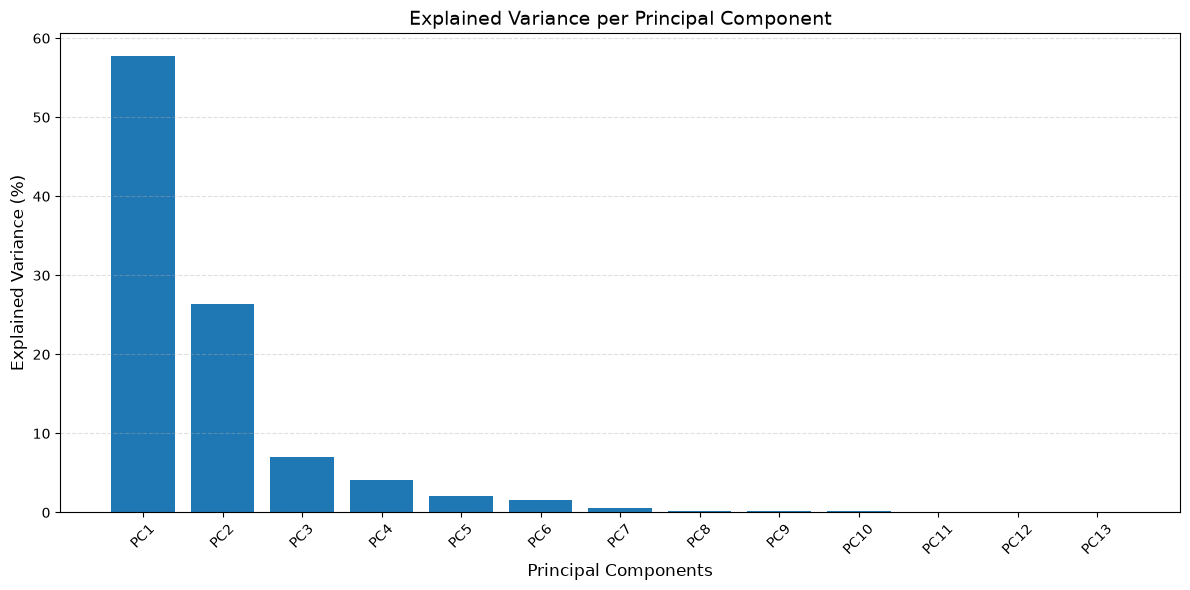

In [36]:
plt.figure(figsize=(12, 6))

plt.bar(
    component_names,
    explained_variance * 100
)

plt.xlabel("Principal Components", fontsize=12)

plt.ylabel("Explained Variance (%)", fontsize=12)

plt.title(
    "Explained Variance per Principal Component",
    fontsize=14
)

plt.xticks(rotation=45)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "explained_variance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

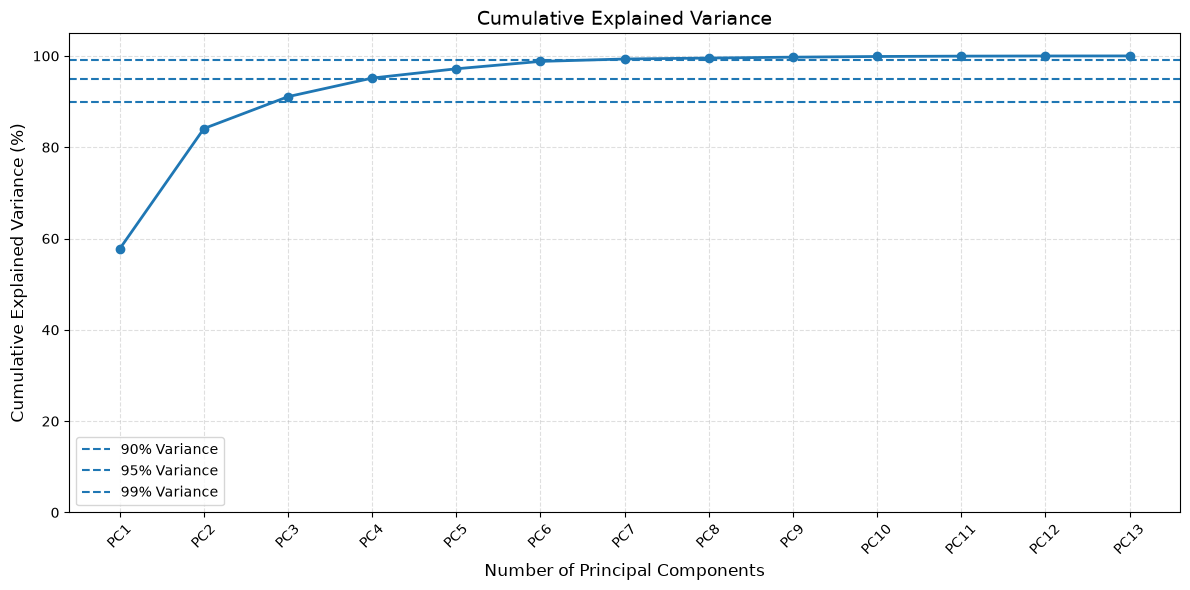

In [37]:
plt.figure(figsize=(12, 6))

plt.plot(
    component_names,
    cumulative_variance * 100,
    marker="o",
    linewidth=2
)

# Variance thresholds
plt.axhline(
    y=90,
    linestyle="--",
    label="90% Variance"
)

plt.axhline(
    y=95,
    linestyle="--",
    label="95% Variance"
)

plt.axhline(
    y=99,
    linestyle="--",
    label="99% Variance"
)

plt.xlabel("Number of Principal Components", fontsize=12)

plt.ylabel("Cumulative Explained Variance (%)", fontsize=12)

plt.title(
    "Cumulative Explained Variance",
    fontsize=14
)

plt.xticks(rotation=45)

plt.ylim(0, 105)

plt.legend()

plt.grid(
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "cumulative_variance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [40]:
scaler_path = PCA_OUTPUT_DIR / "scaler.pkl"

pca_path = PCA_OUTPUT_DIR / "pca_transformer.pkl"

joblib.dump(
    scaler,
    scaler_path
)

joblib.dump(
    pca,
    pca_path
)

print("Preprocessing objects saved successfully.")

print("Scaler:", scaler_path)

print("PCA Transformer:", pca_path)

Preprocessing objects saved successfully.
Scaler: C:\Users\HP\Desktop\NHA-5-151\outputs\pca\phase1\scaler.pkl
PCA Transformer: C:\Users\HP\Desktop\NHA-5-151\outputs\pca\phase1\pca_transformer.pkl


In [41]:
print("-" * 20)

print("PHASE 1: PCA ANALYSIS SUMMARY")

print("-" * 20)

print("\nDataset Information")

print("Total samples:", len(samples))

print("Training samples:", len(train_idx))

print("Validation samples:", len(val_idx))

print("Testing samples:", len(test_idx))

print("\nPCA Information")

print("Original spectral bands:", NUM_BANDS)

print("Available components:", pca.n_components_)

print("\nVariance Retention")

for threshold, count in required_components.items():

    print(
        f"{threshold * 100:.0f}%: "
        f"{count} components"
    )

print("\nGenerated Files")

for file_path in [
    variance_csv_path,
    FIGURES_DIR / "explained_variance.png",
    FIGURES_DIR / "cumulative_variance.png",
    scaler_path,
    pca_path
]:

    print(
        file_path.name,
        "->",
        "EXISTS" if file_path.exists() else "MISSING"
    )

print("\nPhase 1 completed.")

--------------------
PHASE 1: PCA ANALYSIS SUMMARY
--------------------

Dataset Information
Total samples: 27000
Training samples: 18900
Validation samples: 4050
Testing samples: 4050

PCA Information
Original spectral bands: 13
Available components: 13

Variance Retention
90%: 3 components
95%: 4 components
99%: 7 components

Generated Files
explained_variance.csv -> EXISTS
explained_variance.png -> EXISTS
cumulative_variance.png -> EXISTS
scaler.pkl -> EXISTS
pca_transformer.pkl -> EXISTS

Phase 1 completed.


### Phase 2: PCA Scatter Visualization by Class

The PCA visualization uses the first two principal components (PC1 and PC2), which together explain **84.10% of the total variance** in the dataset.

**Class Separation:**

The class-center distance analysis shows that AnnualCrop and PermanentCrop have the smallest distance (0.5099), indicating strong similarity in their average spectral representations. HerbaceousVegetation and Highway also have a small distance (0.5488).

In contrast, AnnualCrop and SeaLake have the largest distance (7.2081), followed by Pasture and SeaLake (6.7278), suggesting greater differences in their average spectral representations.

**Class Overlap:**

The Silhouette Score is **0.0227**, indicating substantial overlap between classes and weak cluster separation in the two-dimensional PCA space.

**Limitations:**

Although PC1 and PC2 preserve 84.10% of the total variance, the remaining 11 components contain approximately 15.90% of the variance. Some class-discriminative information may exist in these components. Therefore, the two-dimensional visualization does not fully represent all spectral information available across the 13 Sentinel-2 bands.

**Conclusion:**

PCA provides a useful two-dimensional representation of the EuroSAT multispectral dataset. However, the low Silhouette Score indicates that the first two principal components alone do not clearly separate all 10 land-cover classes.

In [42]:
# PHASE 2: PCA CLASS VISUALIZATION

import joblib
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# Output directory
PHASE2_DIR = PROJECT_ROOT / "outputs" / "pca" / "phase2"
PHASE2_FIGURES_DIR = PHASE2_DIR / "figures"

PHASE2_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Load saved preprocessing models
scaler = joblib.load(PCA_OUTPUT_DIR / "scaler.pkl")
pca = joblib.load(PCA_OUTPUT_DIR / "pca_transformer.pkl")

# Validate loaded models
assert scaler.n_features_in_ == NUM_BANDS
assert pca.n_features_in_ == NUM_BANDS

print("Phase 2 configuration completed.")
print("Scaler loaded successfully.")
print("PCA transformer loaded successfully.")
print("Number of spectral bands:", NUM_BANDS)
print("Number of samples:", len(samples))
print("Output directory:", PHASE2_FIGURES_DIR)

Phase 2 configuration completed.
Scaler loaded successfully.
PCA transformer loaded successfully.
Number of spectral bands: 13
Number of samples: 27000
Output directory: C:\Users\HP\Desktop\NHA-5-151\outputs\pca\phase2\figures


In [43]:
# Inspect one sample before processing all images

sample_image = dataset.load_multispectral_image(samples[0][0])

print("Image type:", type(sample_image))
print("Image shape:", getattr(sample_image, "shape", None))
print("Image label:", samples[0][1])
print("Label type:", type(samples[0][1]))
print("Class names:", class_names)

Image type: <class 'numpy.ndarray'>
Image shape: (13, 64, 64)
Image label: 0
Label type: <class 'int'>
Class names: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


In [44]:
# Calculate mean spectral values for each image

X_mean = np.zeros((len(samples), NUM_BANDS), dtype=np.float32)
y_labels = np.zeros(len(samples), dtype=np.int64)

for i, sample in enumerate(samples):
    image = dataset.load_multispectral_image(sample[0])

    X_mean[i] = image.mean(axis=(1, 2))
    y_labels[i] = sample[1]

    if (i + 1) % 5000 == 0:
        print(f"Processed {i + 1}/{len(samples)} images")

print("\nMean spectral values shape:", X_mean.shape)
print("Labels shape:", y_labels.shape)
print("Number of classes:", len(np.unique(y_labels)))
print("Class distribution:")

for class_id, class_name in enumerate(class_names):
    print(f"{class_name}: {np.sum(y_labels == class_id)}")

Processed 5000/27000 images
Processed 10000/27000 images
Processed 15000/27000 images
Processed 20000/27000 images
Processed 25000/27000 images

Mean spectral values shape: (27000, 13)
Labels shape: (27000,)
Number of classes: 10
Class distribution:
AnnualCrop: 3000
Forest: 3000
HerbaceousVegetation: 3000
Highway: 2500
Industrial: 2500
Pasture: 2000
PermanentCrop: 2500
Residential: 3000
River: 2500
SeaLake: 3000


In [45]:
# Apply saved preprocessing transformations

X_scaled = scaler.transform(X_mean)
X_pca = pca.transform(X_scaled)

# Extract first two principal components
pca_2d = X_pca[:, :2]

print("Scaled data shape:", X_scaled.shape)
print("PCA transformed data shape:", X_pca.shape)
print("2D PCA data shape:", pca_2d.shape)

print("\nExplained variance:")
print(f"PC1: {pca.explained_variance_ratio_[0] * 100:.2f}%")
print(f"PC2: {pca.explained_variance_ratio_[1] * 100:.2f}%")
print(
    f"Total variance explained by PC1 and PC2: "
    f"{sum(pca.explained_variance_ratio_[:2]) * 100:.2f}%"
)

Scaled data shape: (27000, 13)
PCA transformed data shape: (27000, 13)
2D PCA data shape: (27000, 2)

Explained variance:
PC1: 57.76%
PC2: 26.34%
Total variance explained by PC1 and PC2: 84.09%


In [49]:
# Apply the same reflectance normalization used in Phase 1

X_mean_normalized = X_mean / 10000.0

# Apply saved scaler and PCA (without refitting)
X_scaled = scaler.transform(X_mean_normalized)
X_pca = pca.transform(X_scaled)

# Extract PC1 and PC2
pca_2d = X_pca[:, :2]

print("Normalized mean values:")
print("Min:", X_mean_normalized.min())
print("Max:", X_mean_normalized.max())

print("\nScaled data:")
print("Min:", X_scaled.min())
print("Max:", X_scaled.max())

print("\nPCA coordinates:")
print("PC1 range:", pca_2d[:, 0].min(), "to", pca_2d[:, 0].max())
print("PC2 range:", pca_2d[:, 1].min(), "to", pca_2d[:, 1].max())

print("\nExplained variance:")
print(f"PC1: {pca.explained_variance_ratio_[0] * 100:.2f}%")
print(f"PC2: {pca.explained_variance_ratio_[1] * 100:.2f}%")

Normalized mean values:
Min: 0.00037084962
Max: 0.5837482

Scaled data:
Min: -2.1337607
Max: 30.29666

PCA coordinates:
PC1 range: -5.910088253498199 to 9.107400752913367
PC2 range: -5.121181040694359 to 4.749763025020569

Explained variance:
PC1: 57.76%
PC2: 26.34%


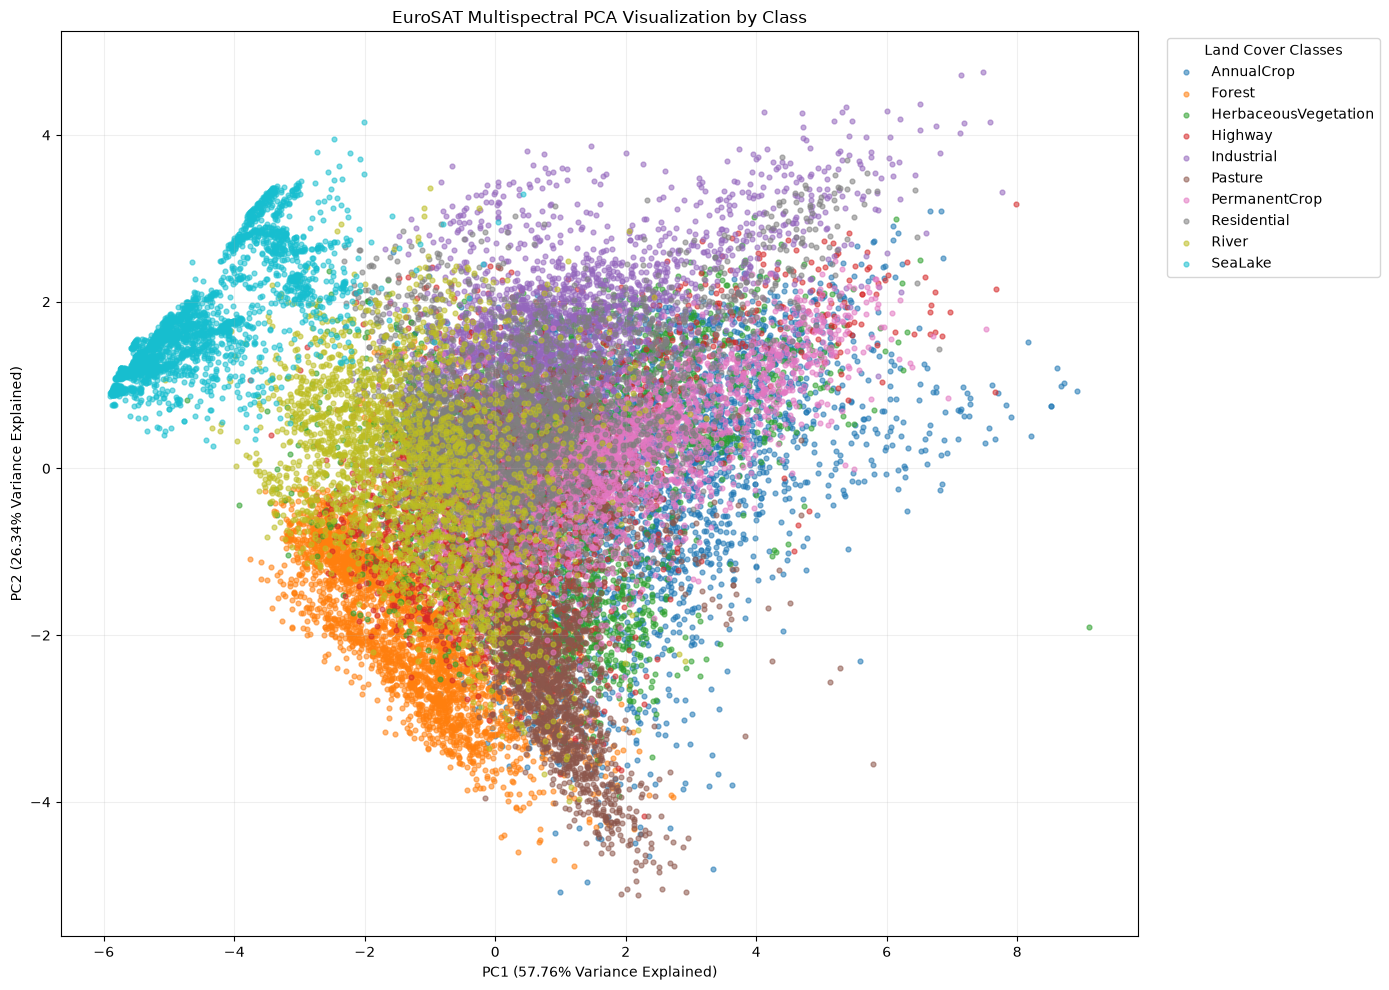

Corrected figure saved: C:\Users\HP\Desktop\NHA-5-151\outputs\pca\phase2\figures\pca_class_visualization.png


In [50]:
# PCA Scatter Visualization by Class (Corrected)

plt.figure(figsize=(14, 10))

colors = plt.cm.tab10(np.linspace(0, 1, len(class_names)))

for class_id, class_name in enumerate(class_names):
    mask = y_labels == class_id

    plt.scatter(
        pca_2d[mask, 0],
        pca_2d[mask, 1],
        label=class_name,
        color=colors[class_id],
        alpha=0.55,
        s=12
    )

pc1_var = pca.explained_variance_ratio_[0] * 100
pc2_var = pca.explained_variance_ratio_[1] * 100

plt.xlabel(f"PC1 ({pc1_var:.2f}% Variance Explained)")
plt.ylabel(f"PC2 ({pc2_var:.2f}% Variance Explained)")
plt.title("EuroSAT Multispectral PCA Visualization by Class")

plt.legend(
    title="Land Cover Classes",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.2)
plt.tight_layout()

figure_path = PHASE2_FIGURES_DIR / "pca_class_visualization.png"

plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Corrected figure saved:", figure_path)

In [51]:
# Quantitative Class Separation Analysis (Corrected)

from sklearn.metrics import silhouette_score

# Calculate class centers
class_centers = {}

for class_id, class_name in enumerate(class_names):
    class_points = pca_2d[y_labels == class_id]
    class_centers[class_name] = class_points.mean(axis=0)

# Calculate distances between class centers
print("Distance Between Class Centers:\n")

for i, name1 in enumerate(class_names):
    for j in range(i + 1, len(class_names)):
        name2 = class_names[j]

        distance = np.linalg.norm(
            class_centers[name1] - class_centers[name2]
        )

        print(f"{name1} - {name2}: {distance:.4f}")

# Calculate Silhouette Score
score = silhouette_score(
    pca_2d,
    y_labels,
    sample_size=5000,
    random_state=42
)

print(f"\nSilhouette Score: {score:.4f}")

Distance Between Class Centers:

AnnualCrop - Forest: 4.0973
AnnualCrop - HerbaceousVegetation: 1.4613
AnnualCrop - Highway: 1.9976
AnnualCrop - Industrial: 2.1474
AnnualCrop - Pasture: 2.3170
AnnualCrop - PermanentCrop: 0.5099
AnnualCrop - Residential: 2.0966
AnnualCrop - River: 3.5938
AnnualCrop - SeaLake: 7.2081
Forest - HerbaceousVegetation: 2.8383
Forest - Highway: 2.3428
Forest - Industrial: 4.4130
Forest - Pasture: 2.3594
Forest - PermanentCrop: 3.8351
Forest - Residential: 3.0468
Forest - River: 1.8515
Forest - SeaLake: 4.8288
HerbaceousVegetation - Highway: 0.5488
HerbaceousVegetation - Industrial: 1.8718
HerbaceousVegetation - Pasture: 1.8755
HerbaceousVegetation - PermanentCrop: 1.0580
HerbaceousVegetation - Residential: 0.9072
HerbaceousVegetation - River: 2.1340
HerbaceousVegetation - SeaLake: 5.8080
Highway - Industrial: 2.1632
Highway - Pasture: 1.8472
Highway - PermanentCrop: 1.6069
Highway - Residential: 0.8994
Highway - River: 1.6200
Highway - SeaLake: 5.3559
Industri

In [48]:
# Validate PCA input and transformed values

print("Mean spectral values:")
print("Min:", X_mean.min())
print("Max:", X_mean.max())
print("Mean:", X_mean.mean())

print("\nScaler statistics:")
print("Scaler mean range:", scaler.mean_.min(), "to", scaler.mean_.max())
print("Scaler scale range:", scaler.scale_.min(), "to", scaler.scale_.max())

print("\nScaled data:")
print("Min:", X_scaled.min())
print("Max:", X_scaled.max())

print("\nPCA coordinates:")
print("PC1 range:", pca_2d[:, 0].min(), "to", pca_2d[:, 0].max())
print("PC2 range:", pca_2d[:, 1].min(), "to", pca_2d[:, 1].max())

print("\nPCA explained variance:")
print(pca.explained_variance_ratio_[:2])

Mean spectral values:
Min: 3.708496
Max: 5837.4824
Mean: 1432.289

Scaler statistics:
Scaler mean range: 0.0012097157649353795 to 0.2596800198976651
Scaler scale range: 0.0004743829580560103 to 0.12298934943581873

Scaled data:
Min: 78.712814
Max: 328464.88

PCA coordinates:
PC1 range: 23906.495587866488 to 174081.38714854562
PC2 range: -34763.715759698935 to 63945.72502497419

PCA explained variance:
[0.5775562 0.2633736]


In [52]:
# Identify the 5 closest class pairs

from itertools import combinations

class_distances = []

for name1, name2 in combinations(class_names, 2):
    distance = np.linalg.norm(
        class_centers[name1] - class_centers[name2]
    )

    class_distances.append((name1, name2, distance))

class_distances.sort(key=lambda x: x[2])

print("5 Closest Class Pairs:\n")

for name1, name2, distance in class_distances[:5]:
    print(f"{name1} - {name2}: {distance:.4f}")

print("\n5 Most Separated Class Pairs:\n")

for name1, name2, distance in class_distances[-5:][::-1]:
    print(f"{name1} - {name2}: {distance:.4f}")

5 Closest Class Pairs:

AnnualCrop - PermanentCrop: 0.5099
HerbaceousVegetation - Highway: 0.5488
Highway - Residential: 0.8994
HerbaceousVegetation - Residential: 0.9072
HerbaceousVegetation - PermanentCrop: 1.0580

5 Most Separated Class Pairs:

AnnualCrop - SeaLake: 7.2081
Pasture - SeaLake: 6.7278
PermanentCrop - SeaLake: 6.7200
Industrial - SeaLake: 5.8562
HerbaceousVegetation - SeaLake: 5.8080


In [53]:
import json
import joblib
from pathlib import Path

# Project paths
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name != "NHA-5-151":
    PROJECT_ROOT = Path(r"C:\Users\HP\Desktop\NHA-5-151")

BASELINE_DIR = PROJECT_ROOT / "outputs" / "baseline"
PHASE1_DIR = PROJECT_ROOT / "outputs" / "pca" / "phase1"

print("=" * 60)
print("PHASE 3 - INITIAL INSPECTION")
print("=" * 60)

# 1. Inspect important project files
files_to_check = [
    "src/dataset_ms.py",
    "src/model.py",
    "src/train.py",
    "data/processed/splits.csv",
    "outputs/baseline/best_model.pth",
    "outputs/baseline/metrics.json",
    "outputs/baseline/metrics.csv",
    "outputs/pca/phase1/scaler.pkl",
    "outputs/pca/phase1/pca_transformer.pkl",
    "outputs/pca/phase1/explained_variance.csv"
]

print("\n1. EXISTING FILES")
for file in files_to_check:
    path = PROJECT_ROOT / file
    print(f"{'FOUND' if path.exists() else 'MISSING'}: {file}")

# 2. Inspect baseline metrics
metrics_path = BASELINE_DIR / "metrics.json"

if metrics_path.exists():
    with open(metrics_path, "r", encoding="utf-8") as f:
        baseline_metrics = json.load(f)

    print("\n2. BASELINE METRICS")
    print(json.dumps(baseline_metrics, indent=2))
else:
    print("\nBaseline metrics JSON not found.")

# 3. Inspect saved PCA objects
scaler_path = PHASE1_DIR / "scaler.pkl"
pca_path = PHASE1_DIR / "pca_transformer.pkl"

if scaler_path.exists() and pca_path.exists():
    scaler = joblib.load(scaler_path)
    pca = joblib.load(pca_path)

    print("\n3. PCA INFORMATION")
    print("Scaler input features:", scaler.n_features_in_)
    print("Scaler fitted samples:", scaler.n_samples_seen_)
    print("PCA input features:", pca.n_features_in_)
    print("PCA fitted samples:", getattr(pca, "n_samples_", "Not available"))
    print("Explained variance (first 5 PCs):")
    print(pca.explained_variance_ratio_[:5])

    print(
        "Cumulative explained variance:",
        pca.explained_variance_ratio_.cumsum()
    )
else:
    print("\nSaved Phase 1 PCA files are missing.")

print("\nInspection completed. No files were modified.")

PHASE 3 - INITIAL INSPECTION

1. EXISTING FILES
FOUND: src/dataset_ms.py
FOUND: src/model.py
FOUND: src/train.py
FOUND: data/processed/splits.csv
MISSING: outputs/baseline/best_model.pth
FOUND: outputs/baseline/metrics.json
FOUND: outputs/baseline/metrics.csv
FOUND: outputs/pca/phase1/scaler.pkl
FOUND: outputs/pca/phase1/pca_transformer.pkl
FOUND: outputs/pca/phase1/explained_variance.csv

2. BASELINE METRICS
{
  "model": "SmallCNN",
  "dataset": "C:\\Users\\HP\\Downloads\\satellite_empty\\EuroSAT_MS\\EuroSAT_MS",
  "num_channels": 13,
  "num_classes": 10,
  "classes": [
    "AnnualCrop",
    "Forest",
    "HerbaceousVegetation",
    "Highway",
    "Industrial",
    "Pasture",
    "PermanentCrop",
    "Residential",
    "River",
    "SeaLake"
  ],
  "seed": 42,
  "device": "cpu",
  "best_epoch": 5,
  "best_validation_loss": 0.19677978565663468,
  "best_validation_accuracy": 0.9365432098765432,
  "test_loss": 0.18618599915210113,
  "test_accuracy": 0.9385185185185185,
  "epochs_complete

In [54]:
import json
import pandas as pd
from pathlib import Path

print("=" * 65)
print("PHASE 3 - DETAILED INSPECTION")
print("=" * 65)

# 1. Baseline metrics
metrics_path = PROJECT_ROOT / "outputs/baseline/metrics.json"

with open(metrics_path, "r", encoding="utf-8") as f:
    baseline_metrics = json.load(f)

print("\n1. BASELINE METRICS")
for key, value in baseline_metrics.items():
    if key == "classes":
        print(f"{key}: {len(value)} classes")
    else:
        print(f"{key}: {value}")

# 2. Baseline CSV
csv_path = PROJECT_ROOT / "outputs/baseline/metrics.csv"

if csv_path.exists():
    baseline_df = pd.read_csv(csv_path)
    print("\n2. BASELINE METRICS CSV")
    print("Columns:", baseline_df.columns.tolist())
    print(baseline_df.tail(3).to_string(index=False))

# 3. PCA explained variance
variance_path = PHASE1_DIR / "explained_variance.csv"

variance_df = pd.read_csv(variance_path)

print("\n3. PCA EXPLAINED VARIANCE")
print("Columns:", variance_df.columns.tolist())
print(variance_df.head(15).to_string(index=False))

# 4. Check possible baseline checkpoints
print("\n4. CHECKPOINT FILES")

for folder in [
    PROJECT_ROOT / "outputs",
    PROJECT_ROOT / "models",
    PROJECT_ROOT / "checkpoints"
]:
    if folder.exists():
        for file in folder.rglob("*.pth"):
            print(file.relative_to(PROJECT_ROOT))

# 5. Inspect project source files
source_files = [
    "src/dataset_ms.py",
    "src/model.py",
    "src/train.py"
]

print("\n5. SOURCE CODE")

for filename in source_files:
    path = PROJECT_ROOT / filename

    print(f"\n{'=' * 20} {filename} {'=' * 20}")

    if path.exists():
        print(path.read_text(encoding="utf-8"))
    else:
        print("File not found.")

print("\nDetailed inspection completed. No files were modified.")

PHASE 3 - DETAILED INSPECTION

1. BASELINE METRICS
model: SmallCNN
dataset: C:\Users\HP\Downloads\satellite_empty\EuroSAT_MS\EuroSAT_MS
num_channels: 13
num_classes: 10
classes: 10 classes
seed: 42
device: cpu
best_epoch: 5
best_validation_loss: 0.19677978565663468
best_validation_accuracy: 0.9365432098765432
test_loss: 0.18618599915210113
test_accuracy: 0.9385185185185185
epochs_completed: 10
training_seconds: 5248.98
hyperparameters: {'batch_size': 32, 'learning_rate': 0.001, 'weight_decay': 0.0001, 'patience': 5, 'min_delta': 0.0001}
artifacts: {'checkpoint': 'C:\\Users\\HP\\Downloads\\satellite_empty\\outputs\\baseline\\best_model.pth', 'classes': 'C:\\Users\\HP\\Downloads\\satellite_empty\\outputs\\baseline\\classes.json', 'history': 'C:\\Users\\HP\\Downloads\\satellite_empty\\outputs\\baseline\\metrics.csv'}

2. BASELINE METRICS CSV
Columns: ['epoch', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy', 'epoch_seconds']
 epoch  train_loss  train_accuracy  val_loss  val_acc

In [55]:
import ast
import json
from pathlib import Path
import pandas as pd

print("=" * 65)
print("PHASE 3 - CHECKPOINT AND PIPELINE VERIFICATION")
print("=" * 65)

# 1. Verify the checkpoint path saved in baseline metrics
checkpoint_path = Path(
    baseline_metrics["artifacts"]["checkpoint"]
)

print("\n1. BASELINE CHECKPOINT")
print("Saved path:", checkpoint_path)
print("Exists:", checkpoint_path.exists())

# Check the current project path too
local_checkpoint = BASELINE_DIR / "best_model.pth"
print("Expected project path:", local_checkpoint)
print("Exists:", local_checkpoint.exists())

# 2. Inspect PCA explained variance
print("\n2. PCA EXPLAINED VARIANCE")

variance_df = pd.read_csv(
    PHASE1_DIR / "explained_variance.csv"
)

print("Columns:", variance_df.columns.tolist())
print(variance_df.head(15).to_string(index=False))

# Calculate K for common variance thresholds
pca = joblib.load(PHASE1_DIR / "pca_transformer.pkl")
cumulative = pca.explained_variance_ratio_.cumsum()

print("\nPC selection:")
for threshold in [0.90, 0.95, 0.99]:
    k = (cumulative >= threshold).argmax() + 1
    print(
        f"{threshold * 100:.0f}% variance: "
        f"{k} PCs ({cumulative[k-1] * 100:.2f}%)"
    )

# 3. Inspect source code structure
print("\n3. SOURCE CODE DEFINITIONS")

for filename in [
    "src/dataset_ms.py",
    "src/model.py",
    "src/train.py"
]:
    path = PROJECT_ROOT / filename
    print(f"\n--- {filename} ---")

    source = path.read_text(encoding="utf-8")
    tree = ast.parse(source)

    for node in tree.body:
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
            print(f"Function: {node.name} (line {node.lineno})")

        elif isinstance(node, ast.ClassDef):
            print(f"Class: {node.name} (line {node.lineno})")

print("\nVerification completed. No files were modified.")

PHASE 3 - CHECKPOINT AND PIPELINE VERIFICATION

1. BASELINE CHECKPOINT
Saved path: C:\Users\HP\Downloads\satellite_empty\outputs\baseline\best_model.pth
Exists: True
Expected project path: C:\Users\HP\Desktop\NHA-5-151\outputs\baseline\best_model.pth
Exists: False

2. PCA EXPLAINED VARIANCE
Columns: ['Component', 'Explained_Variance_Ratio', 'Explained_Variance_Percentage', 'Cumulative_Variance_Ratio', 'Cumulative_Variance_Percentage']
Component  Explained_Variance_Ratio  Explained_Variance_Percentage  Cumulative_Variance_Ratio  Cumulative_Variance_Percentage
      PC1                  0.577556                      57.755620                   0.577556                       57.755620
      PC2                  0.263374                      26.337360                   0.840930                       84.092980
      PC3                  0.069882                       6.988162                   0.910811                       91.081142
      PC4                  0.040707                      

In [56]:
from pathlib import Path
import hashlib

DOWNLOADS_ROOT = Path(r"C:\Users\HP\Downloads\satellite_empty")

print("=" * 65)
print("PHASE 3 - PROJECT CONSISTENCY CHECK")
print("=" * 65)

files_to_compare = [
    "src/dataset_ms.py",
    "src/model.py",
    "src/train.py",
    "data/processed/splits.csv",
    "outputs/baseline/metrics.json",
    "outputs/baseline/metrics.csv",
    "outputs/pca/phase1/scaler.pkl",
    "outputs/pca/phase1/pca_transformer.pkl",
    "outputs/pca/phase1/explained_variance.csv",
    "outputs/baseline/best_model.pth"
]

def get_hash(path):
    if not path.exists():
        return None

    hasher = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            hasher.update(chunk)

    return hasher.hexdigest()

for filename in files_to_compare:
    desktop_file = PROJECT_ROOT / filename
    downloads_file = DOWNLOADS_ROOT / filename

    print(f"\n{filename}")

    print("Desktop exists:", desktop_file.exists())
    print("Downloads exists:", downloads_file.exists())

    if desktop_file.exists() and downloads_file.exists():
        same = get_hash(desktop_file) == get_hash(downloads_file)
        print("Identical files:", same)

print("\nSelected PCA configuration:")
print("K =", 4)
print("Explained variance =", f"{cumulative[3] * 100:.2f}%")
print("Dimensionality reduction =", f"{(1 - 4/13) * 100:.2f}%")

print("\nConsistency check completed. No files were modified.")

PHASE 3 - PROJECT CONSISTENCY CHECK

src/dataset_ms.py
Desktop exists: True
Downloads exists: False

src/model.py
Desktop exists: True
Downloads exists: True
Identical files: False

src/train.py
Desktop exists: True
Downloads exists: True
Identical files: False

data/processed/splits.csv
Desktop exists: True
Downloads exists: True
Identical files: True

outputs/baseline/metrics.json
Desktop exists: True
Downloads exists: True
Identical files: True

outputs/baseline/metrics.csv
Desktop exists: True
Downloads exists: True
Identical files: True

outputs/pca/phase1/scaler.pkl
Desktop exists: True
Downloads exists: False

outputs/pca/phase1/pca_transformer.pkl
Desktop exists: True
Downloads exists: False

outputs/pca/phase1/explained_variance.csv
Desktop exists: True
Downloads exists: False

outputs/baseline/best_model.pth
Desktop exists: False
Downloads exists: True

Selected PCA configuration:
K = 4
Explained variance = 95.15%
Dimensionality reduction = 69.23%

Consistency check completed

In [57]:
import difflib
import hashlib

print("=" * 65)
print("PHASE 3 - CODE AND ARTIFACT DIFFERENCES")
print("=" * 65)

def read_text(path):
    return path.read_text(encoding="utf-8").splitlines()

def file_hash(path):
    if not path.exists():
        return None

    h = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)

    return h.hexdigest()

# 1. Compare model.py and train.py
for filename in ["src/model.py", "src/train.py"]:

    desktop_file = PROJECT_ROOT / filename
    downloads_file = DOWNLOADS_ROOT / filename

    print(f"\n{'=' * 25} {filename} {'=' * 25}")

    if desktop_file.exists() and downloads_file.exists():

        diff = difflib.unified_diff(
            read_text(downloads_file),
            read_text(desktop_file),
            fromfile="Downloads version",
            tofile="Desktop version",
            lineterm=""
        )

        diff_lines = list(diff)

        if diff_lines:
            print("\n".join(diff_lines[:250]))

            if len(diff_lines) > 250:
                print("\n... Remaining differences omitted.")
        else:
            print("Files are identical.")

# 2. Compare important artifacts
print("\n\n2. ARTIFACT COMPARISON")

artifacts = [
    "outputs/baseline/metrics.json",
    "outputs/baseline/metrics.csv",
    "outputs/pca/phase1/scaler.pkl",
    "outputs/pca/phase1/pca_transformer.pkl",
    "outputs/pca/phase1/explained_variance.csv",
    "outputs/baseline/best_model.pth"
]

for filename in artifacts:

    desktop_file = PROJECT_ROOT / filename
    downloads_file = DOWNLOADS_ROOT / filename

    print(f"\n{filename}")

    h1 = file_hash(desktop_file)
    h2 = file_hash(downloads_file)

    print("Desktop:", "FOUND" if h1 else "MISSING")
    print("Downloads:", "FOUND" if h2 else "MISSING")

    if h1 and h2:
        print("Identical:", h1 == h2)

print("\nInspection completed. No files were modified.")

PHASE 3 - CODE AND ARTIFACT DIFFERENCES

========================= src/model.py =========================
--- Downloads version
+++ Desktop version
@@ -1,5 +1,23 @@
+from dataclasses import dataclass
+
 import torch.nn as nn
 from torchvision import models
+from torchvision.models import vgg as torchvision_vgg
+
+
+@dataclass(frozen=True)
+class VGG16Config:
+    classifier_hidden: int = 512
+    dropout: float = 0.5
+    pool_size: int = 1
+
+    def __post_init__(self):
+        if self.classifier_hidden < 1:
+            raise ValueError("classifier_hidden must be positive.")
+        if not 0 <= self.dropout < 1:
+            raise ValueError("dropout must be in [0, 1).")
+        if self.pool_size < 1:
+            raise ValueError("pool_size must be positive.")
 
 
 class SmallCNN(nn.Module):
@@ -8,30 +26,143 @@
 
         def block(i, o):
             return nn.Sequential(
-                nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
-                

In [58]:
import ast

print("=" * 65)
print("PHASE 3 - BASELINE ARCHITECTURE IDENTIFICATION")
print("=" * 65)

for root_name, root in [
    ("DESKTOP", PROJECT_ROOT),
    ("DOWNLOADS", DOWNLOADS_ROOT)
]:

    print(f"\n{'=' * 20} {root_name} {'=' * 20}")

    for filename in ["src/model.py", "src/train.py"]:

        path = root / filename

        print(f"\n--- {filename} ---")

        if not path.exists():
            print("FILE MISSING")
            continue

        source = path.read_text(encoding="utf-8")
        tree = ast.parse(source)

        for node in tree.body:

            if isinstance(node, ast.Import):
                print("Import:", ast.unparse(node))

            elif isinstance(node, ast.ImportFrom):
                print("Import:", ast.unparse(node))

            elif isinstance(node, ast.ClassDef):
                print(f"\nCLASS: {node.name}")

                if filename.endswith("model.py"):
                    print(ast.get_source_segment(source, node))

            elif isinstance(node, ast.FunctionDef):
                print(f"FUNCTION: {node.name}")

                if node.name in [
                    "train_one_epoch",
                    "evaluate",
                    "validate",
                    "main"
                ]:
                    print(ast.get_source_segment(source, node))

# Checkpoint and artifact locations
print("\n\nARTIFACT LOCATIONS")

for root_name, root in [
    ("DESKTOP", PROJECT_ROOT),
    ("DOWNLOADS", DOWNLOADS_ROOT)
]:

    print(f"\n{root_name}")

    for filename in [
        "outputs/baseline/best_model.pth",
        "outputs/baseline/metrics.json",
        "outputs/pca/phase1/scaler.pkl",
        "outputs/pca/phase1/pca_transformer.pkl",
        "outputs/pca/phase1/explained_variance.csv"
    ]:

        path = root / filename
        print(f"{filename}: {'FOUND' if path.exists() else 'MISSING'}")

print("\nInspection only. No files modified.")

PHASE 3 - BASELINE ARCHITECTURE IDENTIFICATION

==================== DESKTOP ====================

--- src/model.py ---
Import: from dataclasses import dataclass
Import: import torch.nn as nn
Import: from torchvision import models
Import: from torchvision.models import vgg as torchvision_vgg

CLASS: VGG16Config
class VGG16Config:
    classifier_hidden: int = 512
    dropout: float = 0.5
    pool_size: int = 1

    def __post_init__(self):
        if self.classifier_hidden < 1:
            raise ValueError("classifier_hidden must be positive.")
        if not 0 <= self.dropout < 1:
            raise ValueError("dropout must be in [0, 1).")
        if self.pool_size < 1:
            raise ValueError("pool_size must be positive.")

CLASS: SmallCNN
class SmallCNN(nn.Module):
    def __init__(self, num_classes, in_channels=3):
        super().__init__()

        def block(i, o):
            return nn.Sequential(
                nn.Conv2d(i, o, 3, padding=1),
                nn.BatchNorm2d(o

In [59]:
import ast

print("=" * 65)
print("ORIGINAL BASELINE - SMALLCNN INSPECTION")
print("=" * 65)

# 1. Original model
model_file = DOWNLOADS_ROOT / "src" / "model.py"

print("\n1. DOWNLOADS MODEL")

if model_file.exists():
    source = model_file.read_text(encoding="utf-8")
    tree = ast.parse(source)

    for node in tree.body:
        if isinstance(node, ast.ClassDef):
            print("\n", ast.get_source_segment(source, node))

        elif isinstance(node, ast.FunctionDef):
            print("\n", ast.get_source_segment(source, node))
else:
    print("model.py not found")

# 2. Original training imports and configuration
train_file = DOWNLOADS_ROOT / "src" / "train.py"

print("\n2. DOWNLOADS TRAINING CONFIGURATION")

if train_file.exists():
    source = train_file.read_text(encoding="utf-8")
    lines = source.splitlines()

    for i, line in enumerate(lines):
        if any(word in line.lower() for word in [
            "smallcnn", "learning_rate", "weight_decay",
            "batch_size", "max_epochs", "patience",
            "crossentropyloss", "adamw", "get_loaders",
            "dataset", "seed"
        ]):
            start = max(0, i - 1)
            end = min(len(lines), i + 2)

            print(f"\nLines {start+1}-{end}:")
            print("\n".join(
                f"{j+1}: {lines[j]}"
                for j in range(start, end)
            ))

# 3. PCA artifact locations
print("\n3. PCA ARTIFACT LOCATIONS")

for root_name, root in [
    ("DESKTOP", PROJECT_ROOT),
    ("DOWNLOADS", DOWNLOADS_ROOT)
]:
    print(f"\n{root_name}")

    for filename in [
        "outputs/pca/phase1/scaler.pkl",
        "outputs/pca/phase1/pca_transformer.pkl",
        "outputs/pca/phase1/explained_variance.csv"
    ]:
        path = root / filename
        print(filename, "FOUND" if path.exists() else "MISSING")

# 4. Dataset files in Downloads
print("\n4. DOWNLOADS DATASET FILES")

for filename in [
    "src/dataset_ms.py",
    "src/dataset.py",
    "data/processed/splits.csv"
]:
    path = DOWNLOADS_ROOT / filename
    print(filename, "FOUND" if path.exists() else "MISSING")

print("\nInspection only. No files modified.")

ORIGINAL BASELINE - SMALLCNN INSPECTION

1. DOWNLOADS MODEL

 class SmallCNN(nn.Module):
    def __init__(self, num_classes, in_channels=3):
        super().__init__()

        def block(i, o):
            return nn.Sequential(
                nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                nn.MaxPool2d(2),
            )

        self.features = nn.Sequential(block(in_channels, 32), block(32, 64), block(64, 128))
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.4), nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.head(self.features(x))

 def build_model(name, num_classes):
    if name == "cnn":
        return SmallCNN(num_classes)
    if name == "resnet18":
        resnet = getattr(models, "ResNet18_Weights", None)
        try:
            weights = resnet.IMAGENET1K_V1 if 

In [61]:
import ast

print("=" * 65)
print("PHASE 3 - DATASET AND PCA PIPELINE VERIFICATION")
print("=" * 65)

# 1. Inspect multispectral dataset loader
dataset_file = PROJECT_ROOT / "src" / "dataset_ms.py"

print("\n1. MULTISPECTRAL DATASET LOADER")

source = dataset_file.read_text(encoding="utf-8")
tree = ast.parse(source)

for node in tree.body:
    if isinstance(node, (ast.ClassDef, ast.FunctionDef)):
        print(f"\n--- {node.name} ---")
        print(ast.get_source_segment(source, node))

import json

notebook_path = PROJECT_ROOT / "notebooks" / "02_pca_analysis.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook_data = json.load(f)

keywords = [
    "iter_pixel_batches",
    "train_idx",
    "StandardScaler",
    "IncrementalPCA",
    "partial_fit",
    "transform",
    "10000",
    "scaler.pkl",
    "pca_transformer.pkl"
]

print("=" * 65)
print("PCA IMPLEMENTATION INSPECTION")
print("=" * 65)

for i, cell in enumerate(notebook_data["cells"]):

    if cell["cell_type"] != "code":
        continue

    code = "".join(cell["source"])

    if any(keyword in code for keyword in keywords):
        print(f"\n{'=' * 20} CELL {i} {'=' * 20}")
        print(code[:6000])

# Inspect saved PCA objects
print("\nSAVED PCA INFORMATION")

print("Scaler input features:", scaler.n_features_in_)
print("PCA input features:", pca.n_features_in_)
print("PCA components:", pca.n_components_)

print("\nInspection completed.")
# 3. Verify saved PCA dimensions
import joblib

scaler = joblib.load(
    PROJECT_ROOT / "outputs/pca/phase1/scaler.pkl"
)

pca = joblib.load(
    PROJECT_ROOT / "outputs/pca/phase1/pca_transformer.pkl"
)

print("\n3. SAVED PCA OBJECTS")
print("Scaler input features:", scaler.n_features_in_)
print("PCA input features:", pca.n_features_in_)
print("PCA components:", pca.n_components_)
print("Selected components:", 4)

print("\nVerification completed. No files modified.")

PHASE 3 - DATASET AND PCA PIPELINE VERIFICATION

1. MULTISPECTRAL DATASET LOADER

--- _contains_class_directories ---
def _contains_class_directories(path):
    return any(
        child.is_dir() and child.name in CLASS_NAMES
        for child in path.iterdir()
    )

--- _find_dataset_root ---
def _find_dataset_root(path):
    if _contains_class_directories(path):
        return path

    for candidate in sorted(
        (child for child in path.rglob("*") if child.is_dir()),
        key=lambda child: (len(child.parts), str(child).lower()),
    ):
        if _contains_class_directories(candidate):
            return candidate

    return None

--- resolve_data_dir ---
def resolve_data_dir(data_dir=None):
    """
    Resolve the dataset directory.

    If data_dir is provided, use it.
    Otherwise, search known EuroSAT MS locations.
    """

    if data_dir is not None:
        path = Path(data_dir).expanduser().resolve()

        if not path.is_dir():
            raise FileNotFoundEr

In [62]:
print("=" * 65)
print("PCA FITTING VERIFICATION")
print("=" * 65)

search_terms = [
    "iter_pixel_batches",
    "partial_fit",
    "fit_transform",
    "scaler.fit",
    "pca.fit",
    "train_idx",
    "StandardScaler",
    "IncrementalPCA"
]

for i, cell in enumerate(notebook_data["cells"]):

    if cell["cell_type"] != "code":
        continue

    code = "".join(cell["source"])
    lines = code.splitlines()

    matched = [
        j for j, line in enumerate(lines)
        if any(term.lower() in line.lower() for term in search_terms)
    ]

    if matched:
        print(f"\n{'=' * 20} CELL {i} {'=' * 20}")

        shown = set()

        for j in matched:
            for k in range(max(0, j-3), min(len(lines), j+5)):
                if k not in shown:
                    print(f"{k+1}: {lines[k]}")
                    shown.add(k)

# Check the number of PCA components
print("\nPCA OBJECT CHECK")
print("Scaler features:", scaler.n_features_in_)
print("PCA features:", pca.n_features_in_)
print("PCA components:", pca.n_components_)
print("Selected K:", 4)

PCA FITTING VERIFICATION

==================== CELL 2 ====================
11: import matplotlib.pyplot as plt
12: 
13: # Machine learning
14: from sklearn.preprocessing import StandardScaler
15: from sklearn.decomposition import IncrementalPCA
16: 
17: # Saving preprocessing objects
18: import joblib
19: 

==================== CELL 9 ====================
3: from pathlib import Path
4: import sys
5: import importlib
6: from sklearn.preprocessing import StandardScaler
7: from sklearn.decomposition import IncrementalPCA
8: import matplotlib.pyplot as plt
9: import joblib
10: 
11: # 2. PROJECT ROOT

==================== CELL 12 ====================
25:     return image
26: 
27: 
28: def iter_pixel_batches(samples, indices, batch_size=8):
29:     """
30:     Generate pixel batches from selected images.
31: 
32:     Each batch has shape:

==================== CELL 13 ====================
9: print("Number of classes:", len(class_names))
10: print("Classes:", class_names)
11: print("samples:"

In [63]:
print("=" * 65)
print("PHASE 1 - PCA FITTING CELLS")
print("=" * 65)

for i in [9, 10, 11, 12, 13]:
    if i < len(notebook_data["cells"]):

        cell = notebook_data["cells"][i]

        print(f"\n{'=' * 25} CELL {i} {'=' * 25}")

        if cell["cell_type"] == "code":
            print("".join(cell["source"]))
        else:
            print("MARKDOWN:")
            print("".join(cell["source"]))

print("\nEnd of Phase 1 inspection.")

PHASE 1 - PCA FITTING CELLS

========================= CELL 9 =========================
# 1. IMPORTS

from pathlib import Path
import sys
import importlib
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import IncrementalPCA
import matplotlib.pyplot as plt
import joblib

# 2. PROJECT ROOT

PROJECT_ROOT = Path(r"C:\Users\HP\Desktop\NHA-5-151")

assert PROJECT_ROOT.exists(), (
    f"Project directory not found: {PROJECT_ROOT}"
)

assert (PROJECT_ROOT / "src" / "dataset.py").exists(), (
    "dataset.py was not found inside the src directory."
)


# 3. PYTHON PATH CONFIGURATION

PROJECT_ROOT_STR = str(PROJECT_ROOT)

if PROJECT_ROOT_STR not in sys.path:
    sys.path.insert(0, PROJECT_ROOT_STR)


# 4. IMPORT DATASET MODULE

import src.dataset_ms as dataset
importlib.reload(dataset)


# 5. IMPORT EXISTING PROJECT FUNCTIONS

resolve_data_dir = dataset.resolve_data_dir
discover_samples = dataset.discover_samples
load_multispectral_image = dataset.load_multispectral_i

In [64]:
print("=" * 65)
print("PCA FITTING OPERATIONS - EXACT CODE")
print("=" * 65)

terms = [
    "scaler.fit",
    "scaler.partial_fit",
    "pca.fit",
    "pca.partial_fit",
    "pca.fit_transform",
    "iter_pixel_batches",
    "train_idx",
    "IMAGE_BATCH_SIZE"
]

for i, cell in enumerate(notebook_data["cells"]):

    if cell["cell_type"] != "code":
        continue

    lines = "".join(cell["source"]).splitlines()

    matched_lines = [
        j for j, line in enumerate(lines)
        if any(term.lower() in line.lower() for term in terms)
    ]

    if matched_lines:
        print(f"\nNOTEBOOK CELL: {i}")
        print("Total lines:", len(lines))

        shown = set()

        for j in matched_lines:
            start = max(0, j - 8)
            end = min(len(lines), j + 12)

            for k in range(start, end):
                if k not in shown:
                    print(f"{k+1}: {lines[k]}")
                    shown.add(k)

            print("-" * 40)

print("\nInspection completed.")

PCA FITTING OPERATIONS - EXACT CODE

NOTEBOOK CELL: 12
Total lines: 68
1: NUM_BANDS = 13
2: IMAGE_HEIGHT = 64
3: IMAGE_WIDTH = 64
4: 
5: PIXELS_PER_IMAGE = IMAGE_HEIGHT * IMAGE_WIDTH
6: 
7: IMAGE_BATCH_SIZE = 8
8: 
9: 
10: def prepare_image_for_pca(image):
11:     """
12:     Apply the same reflectance scaling used by EuroSATMSDataset.
13:     """
14: 
15:     image = np.asarray(image, dtype=np.float32)
16: 
17:     if image.min() < 0:
18:         raise ValueError("Negative reflectance values detected.")
----------------------------------------
20:     if image.max() > 1.0:
21:         image = image / 10000.0
22: 
23:     image = np.clip(image, 0.0, 1.0)
24: 
25:     return image
26: 
27: 
28: def iter_pixel_batches(samples, indices, batch_size=8):
29:     """
30:     Generate pixel batches from selected images.
31: 
32:     Each batch has shape:
33:         (number_of_pixels, 13)
34: 
35:     Only the requested sample indices are processed.
36:     """
37: 
38:     for start in range(

In [65]:
cell_12 = notebook_data["cells"][12]
lines = "".join(cell_12["source"]).splitlines()

print("=" * 65)
print("CELL 12 - REMAINING CODE")
print("=" * 65)

for i in range(18, len(lines)):
    print(f"{i+1}: {lines[i]}")

CELL 12 - REMAINING CODE
19: 
20:     if image.max() > 1.0:
21:         image = image / 10000.0
22: 
23:     image = np.clip(image, 0.0, 1.0)
24: 
25:     return image
26: 
27: 
28: def iter_pixel_batches(samples, indices, batch_size=8):
29:     """
30:     Generate pixel batches from selected images.
31: 
32:     Each batch has shape:
33:         (number_of_pixels, 13)
34: 
35:     Only the requested sample indices are processed.
36:     """
37: 
38:     for start in range(0, len(indices), batch_size):
39: 
40:         batch_indices = indices[start:start + batch_size]
41: 
42:         image_arrays = []
43: 
44:         for sample_index in batch_indices:
45: 
46:             image_path = samples[sample_index][0]
47: 
48:             image = load_multispectral_image(image_path)
49: 
50:             image = prepare_image_for_pca(image)
51: 
52:             if image.shape != (NUM_BANDS, IMAGE_HEIGHT, IMAGE_WIDTH):
53:                 raise ValueError(
54:                     f"Unexpected 

In [66]:
for i in range(27, 66):
    print(f"{i+1}: {lines[i]}")

28: def iter_pixel_batches(samples, indices, batch_size=8):
29:     """
30:     Generate pixel batches from selected images.
31: 
32:     Each batch has shape:
33:         (number_of_pixels, 13)
34: 
35:     Only the requested sample indices are processed.
36:     """
37: 
38:     for start in range(0, len(indices), batch_size):
39: 
40:         batch_indices = indices[start:start + batch_size]
41: 
42:         image_arrays = []
43: 
44:         for sample_index in batch_indices:
45: 
46:             image_path = samples[sample_index][0]
47: 
48:             image = load_multispectral_image(image_path)
49: 
50:             image = prepare_image_for_pca(image)
51: 
52:             if image.shape != (NUM_BANDS, IMAGE_HEIGHT, IMAGE_WIDTH):
53:                 raise ValueError(
54:                     f"Unexpected image shape: {image.shape}"
55:                 )
56: 
57:             # CHW -> HWC -> Pixels x Bands
58:             pixels = image.transpose(1, 2, 0).reshape(
59:              

In [67]:
terms = ["scaler.fit", "scaler.partial_fit", "pca.fit",
         "pca.partial_fit", "partial_fit", "train_idx"]

for i, cell in enumerate(notebook_data["cells"]):
    if cell["cell_type"] != "code":
        continue

    lines = "".join(cell["source"]).splitlines()
    matches = [
        (j, line.strip())
        for j, line in enumerate(lines)
        if any(term in line.lower() for term in terms)
    ]

    if matches:
        print(f"\n--- CELL {i} ---")
        for j, line in matches:
            print(f"Line {j+1}: {line}")


--- CELL 13 ---
Line 12: print("train_idx:", "train_idx" in globals())

--- CELL 18 ---
Line 34: train_idx = splits_df.loc[
Line 47: print("Train samples:", len(train_idx))
Line 51: assert len(train_idx) == 18900

--- CELL 19 ---
Line 8: train_idx,
Line 14: scaler.partial_fit(pixel_batch)

--- CELL 20 ---
Line 11: train_idx,
Line 19: pca.partial_fit(scaled_batch)

--- CELL 26 ---
Line 11: print("Training samples:", len(train_idx))

--- CELL 44 ---
Line 28: "train_idx",
Line 31: "partial_fit",


In [68]:
# ==========================================
# PHASE 3 - PCA MODEL COMPARISON
# ==========================================

import os
import time
import json
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# PCA configuration
N_COMPONENTS = 4
NUM_CLASSES = 10

# Training configuration
BATCH_SIZE = 32
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 30
PATIENCE = 5

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Output directories
PHASE3_DIR = PROJECT_ROOT / "outputs" / "pca" / "phase3"
MODEL_DIR = PHASE3_DIR / "models"
FIGURE_DIR = PHASE3_DIR / "figures"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Device:", DEVICE)
print("PCA Components:", N_COMPONENTS)
print("Output:", PHASE3_DIR)

Device: cpu
PCA Components: 4
Output: C:\Users\HP\Desktop\NHA-5-151\outputs\pca\phase3


In [69]:
# ==========================================
# VERIFY PCA AND SCALER
# ==========================================

assert scaler.n_features_in_ == 13
assert pca.n_features_in_ == 13
assert pca.n_components_ == 13

assert len(cumulative) >= N_COMPONENTS
assert cumulative[N_COMPONENTS - 1] >= 0.95

print("Scaler features:", scaler.n_features_in_)
print("PCA components:", pca.n_components_)
print("Selected components:", N_COMPONENTS)

print(
    "Explained variance:",
    f"{cumulative[N_COMPONENTS - 1] * 100:.2f}%"
)

print(
    "Dimensionality reduction:",
    f"{(1 - N_COMPONENTS / 13) * 100:.2f}%"
)

Scaler features: 13
PCA components: 13
Selected components: 4
Explained variance: 95.15%
Dimensionality reduction: 69.23%


In [70]:
# ==========================================
# VERIFY DATA SPLITS
# ==========================================

print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

assert len(train_idx) == 18900
assert len(val_idx) == 4050
assert len(test_idx) == 4050

assert len(set(train_idx) & set(val_idx)) == 0
assert len(set(train_idx) & set(test_idx)) == 0
assert len(set(val_idx) & set(test_idx)) == 0

print("Splits verified successfully.")

Train: 18900
Validation: 4050
Test: 4050
Splits verified successfully.


In [71]:
# ==========================================
# TRANSFORM IMAGES USING PCA
# ==========================================

def transform_image_pca(image):

    image = prepare_image_for_pca(image)

    if image.shape != (13, 64, 64):
        raise ValueError(f"Unexpected image shape: {image.shape}")

    # (13, 64, 64) -> (4096, 13)
    pixels = image.reshape(13, -1).T

    # Apply existing scaler
    scaled_pixels = scaler.transform(pixels)

    # Apply existing PCA
    transformed_pixels = pca.transform(scaled_pixels)

    # Select first 4 components
    transformed_pixels = transformed_pixels[:, :N_COMPONENTS]

    # (4096, 4) -> (4, 64, 64)
    transformed_image = transformed_pixels.T.reshape(
        N_COMPONENTS, 64, 64
    )

    return transformed_image.astype(np.float32)


print("PCA image transformation function is ready.")

PCA image transformation function is ready.


In [77]:
# ==========================================
# PCA DATASET
# ==========================================

class PCAEuroSATDataset(Dataset):

    def __init__(self, samples, indices):

        self.samples = samples
        self.indices = indices

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):

        sample_index = self.indices[index]

        image_path, label, class_name = self.samples[sample_index]

        image = load_multispectral_image(image_path)

        image = transform_image_pca(image)

        return (
            torch.tensor(image, dtype=torch.float32),
            torch.tensor(int(label), dtype=torch.long)
        )


print("PCA Dataset class is ready.")

PCA Dataset class is ready.


In [78]:
# ==========================================
# CREATE TRAIN / VALIDATION / TEST DATASETS
# ==========================================

train_dataset = PCAEuroSATDataset(samples, train_idx)
val_dataset = PCAEuroSATDataset(samples, val_idx)
test_dataset = PCAEuroSATDataset(samples, test_idx)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 18900
Validation: 4050
Test: 4050


In [79]:
# ==========================================
# DATA LOADERS
# ==========================================

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("DataLoaders created successfully.")

DataLoaders created successfully.


In [80]:
print("Sample example:")
print(samples[0])

print("\nSample type:")
print(type(samples[0]))

print("\nNumber of values:")
print(len(samples[0]))

Sample example:
(WindowsPath('C:/Users/HP/Downloads/satellite_empty/EuroSAT_MS/EuroSAT_MS/AnnualCrop/AnnualCrop_1.tif'), 0, 'AnnualCrop')

Sample type:
<class 'tuple'>

Number of values:
3


In [81]:
# ==========================================
# VERIFY PCA OUTPUT SHAPE
# ==========================================

images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

assert images.shape[1:] == (4, 64, 64)
assert labels.ndim == 1

print("PCA output verified.")

Images shape: torch.Size([32, 4, 64, 64])
Labels shape: torch.Size([32])
PCA output verified.


In [83]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cpu


In [84]:
import torch
import torch.nn as nn

class PCASmallCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(4, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = PCASmallCNN(num_classes=10).to(device)

print(model)
print(f"Device: {device}")

PCASmallCNN(
  (features): Sequential(
    (0): Conv2d(4, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU()
    (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Conv2d(64, 128, 

In [85]:
import torch.optim as optim
import random
import numpy as np
import time
from pathlib import Path

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

MAX_EPOCHS = 30
PATIENCE = 5

phase3_dir = Path("outputs/pca/phase3")
models_dir = phase3_dir / "models"

models_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path = models_dir / "pca_smallcnn_best.pth"

print("Training setup completed.")
print("Checkpoint:", checkpoint_path)

Training setup completed.
Checkpoint: outputs\pca\phase3\models\pca_smallcnn_best.pth


In [86]:
def run_epoch(model, loader, criterion, optimizer=None):
    is_training = optimizer is not None

    model.train() if is_training else model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.set_grad_enabled(is_training):

        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            if is_training:
                optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            if is_training:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    average_loss = total_loss / total
    accuracy = correct / total

    return average_loss, accuracy

In [87]:
history = []

best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0

training_start = time.time()

for epoch in range(1, MAX_EPOCHS + 1):

    epoch_start = time.time()

    train_loss, train_acc = run_epoch(
        model, train_loader, criterion, optimizer
    )

    val_loss, val_acc = run_epoch(
        model, val_loader, criterion
    )

    epoch_time = time.time() - epoch_start

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "epoch_time": epoch_time
    })

    print(
        f"Epoch [{epoch}/{MAX_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Time: {epoch_time:.1f}s"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(model.state_dict(), checkpoint_path)

        print("Best model saved.")

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

training_seconds = time.time() - training_start

print("\nTraining completed.")
print(f"Best epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Training time: {training_seconds:.2f} seconds")

Epoch [1/30] | Train Loss: 0.8135 | Train Acc: 0.7316 | Val Loss: 0.4916 | Val Acc: 0.8210 | Time: 307.7s
Best model saved.
Epoch [2/30] | Train Loss: 0.4891 | Train Acc: 0.8388 | Val Loss: 0.2811 | Val Acc: 0.9086 | Time: 239.8s
Best model saved.
Epoch [3/30] | Train Loss: 0.3791 | Train Acc: 0.8750 | Val Loss: 0.3840 | Val Acc: 0.8798 | Time: 238.9s
Epoch [4/30] | Train Loss: 0.3227 | Train Acc: 0.8933 | Val Loss: 0.2260 | Val Acc: 0.9210 | Time: 240.8s
Best model saved.
Epoch [5/30] | Train Loss: 0.2987 | Train Acc: 0.9010 | Val Loss: 0.2205 | Val Acc: 0.9259 | Time: 242.9s
Best model saved.
Epoch [6/30] | Train Loss: 0.2623 | Train Acc: 0.9147 | Val Loss: 0.1902 | Val Acc: 0.9294 | Time: 239.9s
Best model saved.
Epoch [7/30] | Train Loss: 0.2370 | Train Acc: 0.9238 | Val Loss: 0.1479 | Val Acc: 0.9521 | Time: 239.7s
Best model saved.
Epoch [8/30] | Train Loss: 0.2121 | Train Acc: 0.9315 | Val Loss: 0.1519 | Val Acc: 0.9514 | Time: 239.7s
Epoch [9/30] | Train Loss: 0.2068 | Train Ac

In [88]:

model.load_state_dict(
    torch.load(checkpoint_path, map_location=device)
)

model.eval()

print("Best PCA model loaded successfully.")

Best PCA model loaded successfully.


In [89]:
test_loss, test_accuracy = run_epoch(
    model,
    test_loader,
    criterion
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Loss: 0.0738
Test Accuracy: 97.48%


In [90]:
import pandas as pd

history_df = pd.DataFrame(history)

history_path = phase3_dir / "pca_training_history.csv"
history_df.to_csv(history_path, index=False)

print("Training history saved:", history_path)

Training history saved: outputs\pca\phase3\pca_training_history.csv


In [91]:
model.load_state_dict(
    torch.load(checkpoint_path, map_location=device)
)

model.eval()

print("Best PCA model loaded successfully.")

Best PCA model loaded successfully.


In [92]:
test_loss, test_accuracy = run_epoch(
    model,
    test_loader,
    criterion
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Loss: 0.0738
Test Accuracy: 97.48%


In [93]:
pca_metrics = {
    "test_accuracy": test_accuracy,
    "test_loss": test_loss,
    "best_epoch": best_epoch,
    "best_validation_loss": best_val_loss,
    "epochs_completed": len(history),
    "training_seconds": training_seconds,
    "input_channels": 4,
    "explained_variance": 0.95151815,
    "dimensionality_reduction": 0.6923,
    "device": str(device)
}

import json

metrics_path = phase3_dir / "pca_model_metrics.json"

with open(metrics_path, "w") as f:
    json.dump(pca_metrics, f, indent=4)

print("Metrics saved:", metrics_path)

Metrics saved: outputs\pca\phase3\pca_model_metrics.json


In [95]:
from pathlib import Path

possible_paths = [
    Path("outputs/baseline/metrics.json"),
    Path.home() / "Downloads/satellite_empty/outputs/baseline/metrics.json",
    Path.home() / "Desktop/NHA-5-151/outputs/baseline/metrics.json"
]

baseline_path = None

for path in possible_paths:
    if path.exists():
        baseline_path = path
        break

if baseline_path:
    print("Baseline metrics found:", baseline_path)
else:
    print("Baseline metrics file not found.")

Baseline metrics found: C:\Users\HP\Downloads\satellite_empty\outputs\baseline\metrics.json


In [96]:
import json
import pandas as pd

# Load Baseline metrics
with open(baseline_path, "r") as f:
    baseline_metrics = json.load(f)

# Load PCA metrics
with open(phase3_dir / "pca_model_metrics.json", "r") as f:
    pca_metrics = json.load(f)

comparison = pd.DataFrame([
    {
        "Model": "Baseline CNN",
        "Input Channels": 13,
        "Test Accuracy": baseline_metrics["test_accuracy"],
        "Test Loss": baseline_metrics["test_loss"],
        "Training Time (seconds)": baseline_metrics["training_seconds"],
        "Best Epoch": baseline_metrics["best_epoch"],
        "Dimensionality Reduction": "0%"
    },
    {
        "Model": "PCA CNN",
        "Input Channels": 4,
        "Test Accuracy": pca_metrics["test_accuracy"],
        "Test Loss": pca_metrics["test_loss"],
        "Training Time (seconds)": pca_metrics["training_seconds"],
        "Best Epoch": pca_metrics["best_epoch"],
        "Dimensionality Reduction": "69.23%"
    }
])

comparison_path = phase3_dir / "pca_baseline_comparison.csv"
comparison.to_csv(comparison_path, index=False)

display(comparison)

print("Saved:", comparison_path)

,Model,Input Channels,Test Accuracy,Test Loss,Training Time (seconds),Best Epoch,Dimensionality Reduction
0,Baseline CNN,13,0.938519,0.186186,5248.980000,5,0%
1,PCA CNN,4,0.974815,0.073766,6324.073747,21,69.23%


Saved: outputs\pca\phase3\pca_baseline_comparison.csv


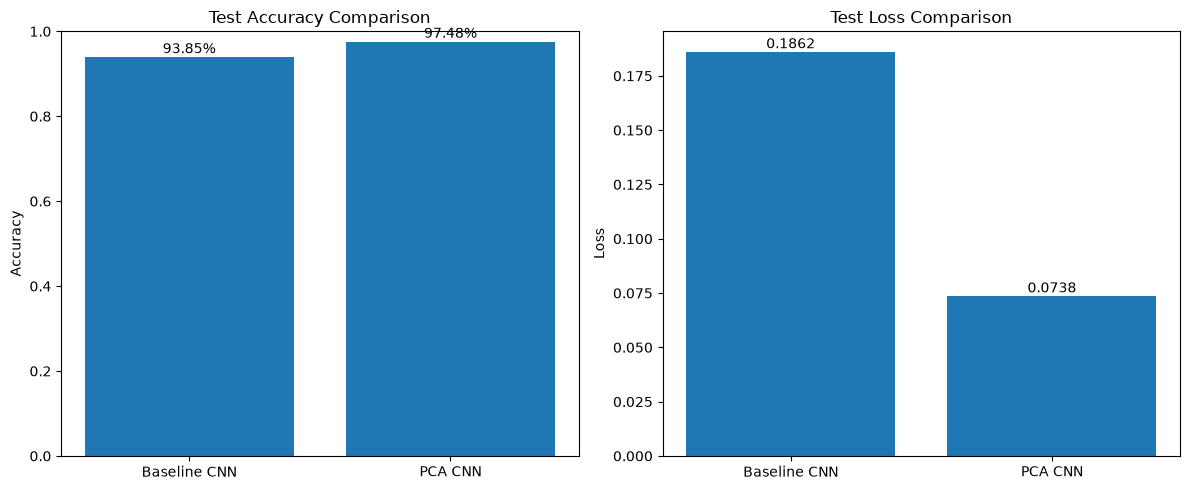

Figure saved: outputs\pca\phase3\figures\baseline_vs_pca.png


In [97]:
import matplotlib.pyplot as plt

models = comparison["Model"].tolist()
accuracies = comparison["Test Accuracy"].tolist()
losses = comparison["Test Loss"].tolist()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Accuracy comparison
axes[0].bar(models, accuracies)
axes[0].set_title("Test Accuracy Comparison")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1)

for i, value in enumerate(accuracies):
    axes[0].text(i, value + 0.01, f"{value:.2%}", ha="center")

# Loss comparison
axes[1].bar(models, losses)
axes[1].set_title("Test Loss Comparison")
axes[1].set_ylabel("Loss")

for i, value in enumerate(losses):
    axes[1].text(i, value, f"{value:.4f}", ha="center", va="bottom")

plt.tight_layout()

figure_path = phase3_dir / "figures" / "baseline_vs_pca.png"
figure_path.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", figure_path)

In [98]:
required_files = [
    phase3_dir / "pca_baseline_comparison.csv",
    phase3_dir / "pca_model_metrics.json",
    phase3_dir / "pca_training_history.csv",
    phase3_dir / "figures" / "baseline_vs_pca.png",
    phase3_dir / "models" / "pca_smallcnn_best.pth"
]

print("PHASE 3 FINAL CHECK\n")

for file in required_files:
    status = "FOUND" if file.exists() else "MISSING"
    print(f"{status}: {file}")

if all(file.exists() for file in required_files):
    print("\nPhase 3 outputs completed successfully!")
else:
    print("\nSome files are missing. Check the paths above.")

PHASE 3 FINAL CHECK

FOUND: outputs\pca\phase3\pca_baseline_comparison.csv
FOUND: outputs\pca\phase3\pca_model_metrics.json
FOUND: outputs\pca\phase3\pca_training_history.csv
FOUND: outputs\pca\phase3\figures\baseline_vs_pca.png
FOUND: outputs\pca\phase3\models\pca_smallcnn_best.pth

Phase 3 outputs completed successfully!
